In [1]:

import torch
import torchvision
import os

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

PROJECT_DIR = "/content/drive/MyDrive/AgriDoctor_AI"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/data", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/models", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/outputs", exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Folders:", os.listdir(PROJECT_DIR))


Project folder: /content/drive/MyDrive/AgriDoctor_AI
Folders: ['models', 'app.py', 'data', 'outputs']


In [4]:

%pip install -q importlib_resources


In [5]:


import os
import subprocess

PROJECT_DIR = "/content/drive/MyDrive/AgriDoctor_AI"
DATA_DIR = f"{PROJECT_DIR}/data/PlantVillage"

os.makedirs(os.path.dirname(DATA_DIR), exist_ok=True)

repo_url = "https://github.com/techannu/PlantVillage.git"

result = subprocess.run(
    ["git", "clone", "--depth", "1", repo_url, DATA_DIR],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("Repository downloaded.")
else:
    print("Download failed. Check the error above.")



Cloning into '/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage'...
Updating files:   0% (157/54308)
Updating files:   0% (277/54308)
Updating files:   0% (413/54308)
Updating files:   1% (544/54308)
Updating files:   1% (550/54308)
Updating files:   1% (686/54308)
Updating files:   1% (815/54308)
Updating files:   1% (901/54308)
Updating files:   1% (1000/54308)
Updating files:   2% (1087/54308)
Updating files:   2% (1106/54308)
Updating files:   2% (1211/54308)
Updating files:   2% (1318/54308)
Updating files:   2% (1422/54308)
Updating files:   2% (1528/54308)
Updating files:   3% (1630/54308)
Updating files:   3% (1632/54308)
Updating files:   3% (1738/54308)
Updating files:   3% (1841/54308)
Updating files:   3% (1947/54308)
Updating files:   3% (2040/54308)
Updating files:   3% (2143/54308)
Updating files:   4% (2173/54308)
Updating files:   4% (2272/54308)
Updating files:   4% (2382/54308)
Updating files:   4% (2488/54308)
Updating files:   4% (2600/54308)
Updating files: 

In [6]:

from pathlib import Path

root = Path("/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage")

image_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".PNG"}

image_count = sum(
    1 for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

class_folders = [
    p for p in root.rglob("*")
    if p.is_dir() and any(
        f.is_file() and f.suffix.lower() in image_extensions
        for f in p.iterdir()
    )
]

print("Image count:", image_count)
print("Folders containing images:", len(class_folders))
print("Example folders:", [p.name for p in class_folders[:10]])


Image count: 54304
Folders containing images: 39
Example folders: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']


In [7]:

from pathlib import Path
from PIL import Image
from collections import Counter

DATA_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

class_counts = {}

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        ]
        if images:
            class_counts[folder.name] = len(images)

print("Number of classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

print("\nImages per class:")
for name, count in class_counts.items():
    print(f"{name}: {count}")

print("\nSmallest class:", min(class_counts.values()))
print("Largest class:", max(class_counts.values()))


Number of classes: 39
Total images: 54304

Images per class:
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 853
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1476
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5089
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato_

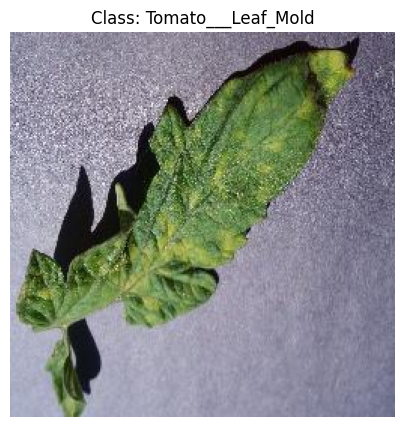

Image size: (256, 256)


In [8]:

import matplotlib.pyplot as plt
from PIL import Image
import random

valid_classes = list(class_counts.keys())
sample_class = random.choice(valid_classes)

sample_files = [
    p for p in (DATA_DIR / sample_class).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

sample_path = random.choice(sample_files)

img = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title(f"Class: {sample_class}")
plt.axis("off")
plt.show()

print("Image size:", img.size)


In [9]:

%pip install -q scikit-learn

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.model_selection import train_test_split

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
GPU available: True


In [10]:

from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing ready!")


Image preprocessing ready!


In [11]:


from pathlib import Path
import os

SOURCE_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage"
)

CLEAN_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage_Clean"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".ppm", ".pgm", ".tif", ".tiff"
}

CLEAN_DIR.mkdir(parents=True, exist_ok=True)

for folder in sorted(SOURCE_DIR.iterdir()):
    if not folder.is_dir() or folder.name.startswith("."):
        continue

    has_images = any(
        p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        for p in folder.iterdir()
    )

    if has_images:
        destination = CLEAN_DIR / folder.name

        if not destination.exists():
            os.symlink(folder.resolve(), destination)

print("Clean dataset created!")
print("Class folders:", len([
    p for p in CLEAN_DIR.iterdir() if p.is_dir()
]))




Clean dataset created!
Class folders: 39


In [12]:

from torchvision.datasets import ImageFolder
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = ImageFolder(
    root=str(CLEAN_DIR),
    transform=transform
)

print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print("Class names:")
for name in dataset.classes:
    print(name)


Total images: 54304
Number of classes: 39
Class names:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato_

In [13]:

from pathlib import Path
from torchvision.datasets import ImageFolder
from torchvision import transforms

CLEAN_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage_Clean"
)

REMOVED_CLASS = "x_Removed_from_Healthy_leaves"

# Exclude the non-target folder from the class list.
class_names = sorted(
    p.name for p in CLEAN_DIR.iterdir()
    if p.is_dir()
    and not p.name.startswith(".")
    and p.name != REMOVED_CLASS
)

print("Target classes:", len(class_names))
print("Excluded folder:", REMOVED_CLASS)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ImageFolder normally includes every class directory.
# Use a dedicated folder containing only the 38 target classes.
import os

TRAIN_SOURCE = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/PlantVillage_38"
)
TRAIN_SOURCE.mkdir(parents=True, exist_ok=True)

for name in class_names:
    link = TRAIN_SOURCE / name
    source = CLEAN_DIR / name

    if not link.exists():
        os.symlink(source.resolve(), link)

dataset = ImageFolder(
    root=str(TRAIN_SOURCE),
    transform=transform
)

print("Loaded classes:", len(dataset.classes))
print("Loaded images:", len(dataset))


Target classes: 38
Excluded folder: x_Removed_from_Healthy_leaves
Loaded classes: 38
Loaded images: 54299


In [14]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

indices = list(range(len(dataset)))
targets = dataset.targets

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=targets
)

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Total:", len(train_dataset) + len(val_dataset))


Training images: 43439
Validation images: 10860
Total: 54299


In [15]:

import torch
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("GPU available:", torch.cuda.is_available())


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
GPU available: True


In [16]:

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = len(dataset.classes)

# Load ResNet18 with pretrained ImageNet weights
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Freeze the pretrained feature layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, NUM_CLASSES)

model = model.to(device)

print("Device:", device)
print("Number of classes:", NUM_CLASSES)
print("Final layer:", model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 67.1MB/s]


Device: cuda
Number of classes: 38
Final layer: Linear(in_features=512, out_features=38, bias=True)


In [17]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [18]:

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Expected output:", (images.shape[0], NUM_CLASSES))
print("Forward pass successful!")


Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 38])
Expected output: (32, 38)
Forward pass successful!


In [19]:

import torch

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    # Keep frozen backbone BatchNorm layers in evaluation mode
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


print("Training functions defined successfully!")


Training functions defined successfully!


In [20]:

EPOCHS = 3

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )


Epoch 1/3 | Train Loss: 0.5151 | Train Acc: 88.36% | Val Loss: 0.2150 | Val Acc: 94.24%
Epoch 2/3 | Train Loss: 0.1770 | Train Acc: 95.21% | Val Loss: 0.1553 | Val Acc: 95.46%
Epoch 3/3 | Train Loss: 0.1320 | Train Acc: 96.25% | Val Loss: 0.1379 | Val Acc: 95.87%


In [21]:

import os
import torch

MODEL_DIR = "/content/drive/MyDrive/AgriDoctor_AI/models"
os.makedirs(MODEL_DIR, exist_ok=True)

baseline_path = os.path.join(
    MODEL_DIR, "resnet18_baseline.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": dataset.classes,
    "num_classes": len(dataset.classes),
    "history": history
}, baseline_path)

print("Baseline model saved successfully!")
print("Location:", baseline_path)


Baseline model saved successfully!
Location: /content/drive/MyDrive/AgriDoctor_AI/models/resnet18_baseline.pth


In [22]:

# Unfreeze the last ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep earlier layers frozen
for param in model.parameters():
    param.requires_grad = False

# Re-enable training for layer4 and the final classifier
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

# Use a smaller learning rate for fine-tuning
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 0.0001},
    {"params": model.fc.parameters(), "lr": 0.0001}
])

print("Fine-tuning setup completed!")
print("Trainable layers: layer4 and fc")


Fine-tuning setup completed!
Trainable layers: layer4 and fc


In [23]:

FINE_TUNE_EPOCHS = 3

fine_tune_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(FINE_TUNE_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    fine_tune_history["train_loss"].append(train_loss)
    fine_tune_history["train_acc"].append(train_acc)
    fine_tune_history["val_loss"].append(val_loss)
    fine_tune_history["val_acc"].append(val_acc)

    print(
        f"Fine-tune Epoch {epoch + 1}/{FINE_TUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )


Fine-tune Epoch 1/3 | Train Loss: 0.0978 | Train Acc: 97.00% | Val Loss: 0.0722 | Val Acc: 97.73%
Fine-tune Epoch 2/3 | Train Loss: 0.0249 | Train Acc: 99.11% | Val Loss: 0.0371 | Val Acc: 98.86%
Fine-tune Epoch 3/3 | Train Loss: 0.0172 | Train Acc: 99.46% | Val Loss: 0.0395 | Val Acc: 98.85%


In [ ]:

import os
import torch

MODEL_DIR = "/content/drive/MyDrive/AgriDoctor_AI/models"
os.makedirs(MODEL_DIR, exist_ok=True)

fine_tuned_path = os.path.join(
    MODEL_DIR, "resnet18_finetuned.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": dataset.classes,
    "num_classes": len(dataset.classes),
    "baseline_history": history,
    "fine_tune_history": fine_tune_history
}, fine_tuned_path)

print("Fine-tuned model saved successfully!")
print("Path:", fine_tuned_path)
print("Number of classes:", len(dataset.classes))


In [25]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch

model.eval()
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(dataset.classes))),
    target_names=dataset.classes,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(dataset.classes)))
)

print("Confusion matrix shape:", cm.shape)
print("Total evaluated images:", len(all_labels))


                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    0.9921    0.9960       126
                                 Apple___Black_rot     1.0000    1.0000    1.0000       124
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        55
                                   Apple___healthy     0.9970    0.9970    0.9970       329
                               Blueberry___healthy     1.0000    0.9967    0.9983       300
          Cherry_(including_sour)___Powdery_mildew     0.9953    1.0000    0.9976       210
                 Cherry_(including_sour)___healthy     1.0000    0.9942    0.9971       171
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9765    0.8058    0.8830       103
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       238
               Corn_(maize)___Northern_Leaf_Blight     0.9070    0.9898    0.94

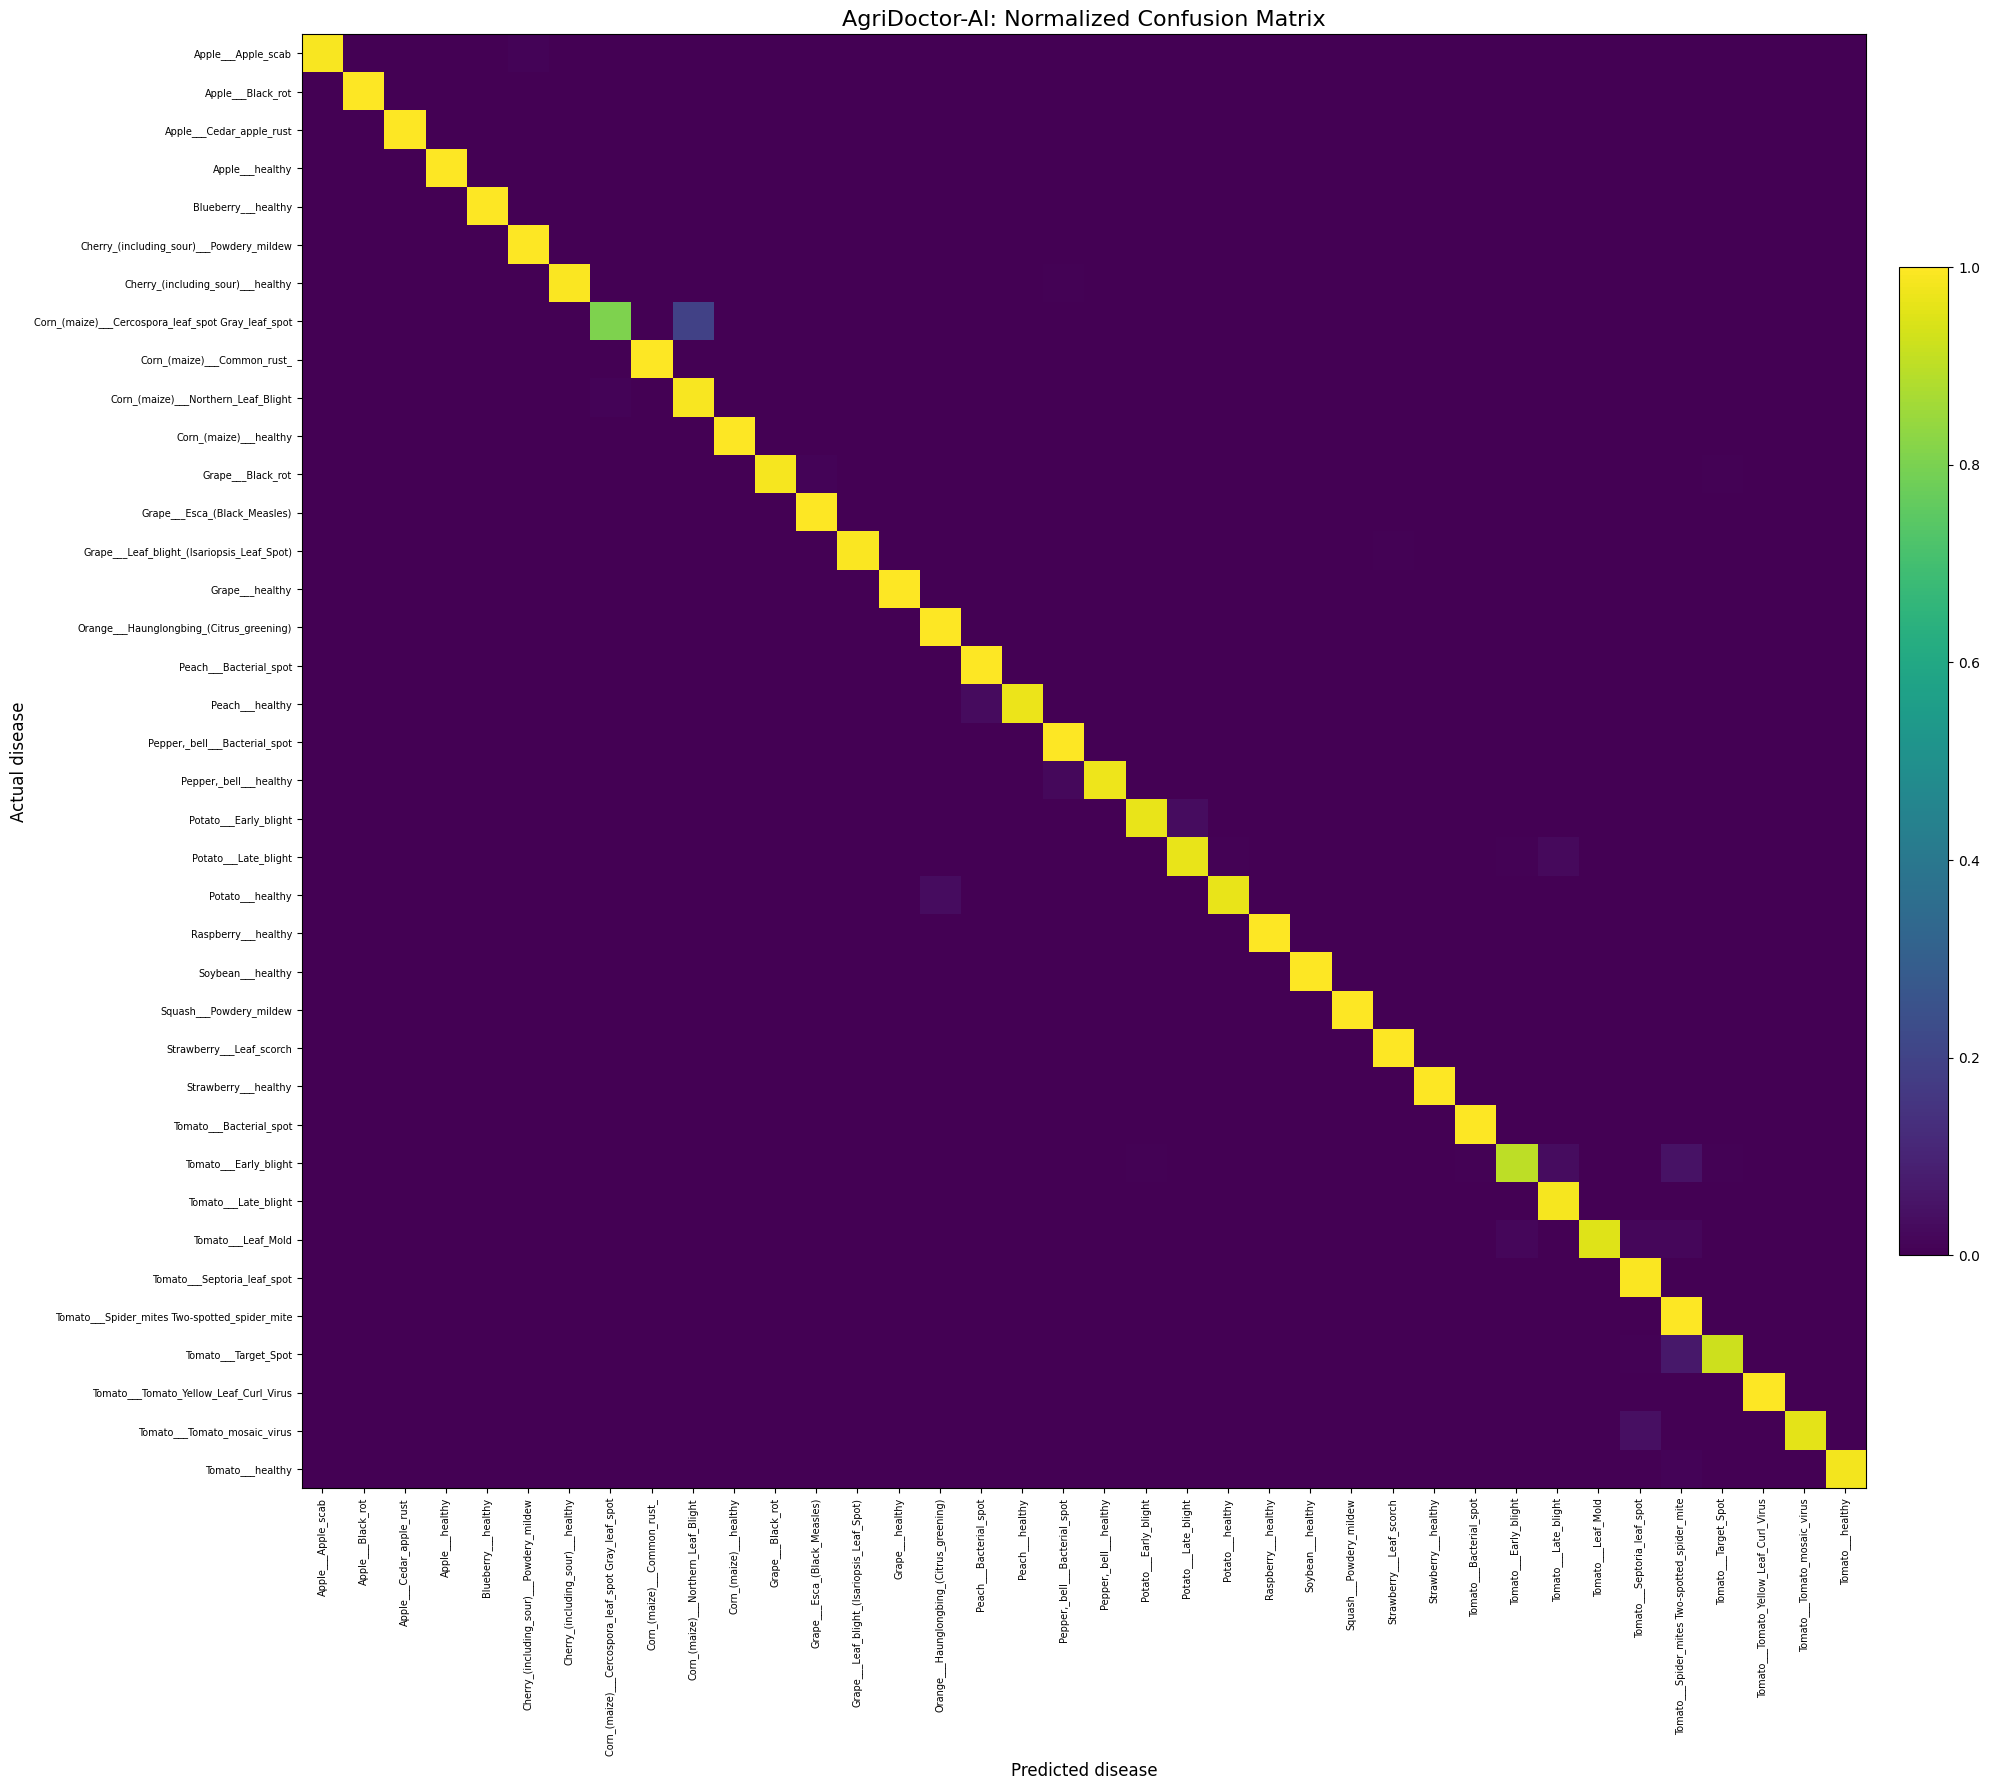

Confusion matrix saved to: /content/drive/MyDrive/AgriDoctor_AI/outputs/normalized_confusion_matrix.png


In [26]:

import os
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = "/content/drive/MyDrive/AgriDoctor_AI/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Normalize each row to show the recall for each true class
row_totals = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(20, 18))

image = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "AgriDoctor-AI: Normalized Confusion Matrix",
    fontsize=16
)
ax.set_xlabel("Predicted disease", fontsize=12)
ax.set_ylabel("Actual disease", fontsize=12)

ax.set_xticks(np.arange(len(dataset.classes)))
ax.set_yticks(np.arange(len(dataset.classes)))

ax.set_xticklabels(
    dataset.classes, rotation=90, fontsize=7
)
ax.set_yticklabels(dataset.classes, fontsize=7)

fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
plt.tight_layout()

matrix_path = os.path.join(
    OUTPUT_DIR, "normalized_confusion_matrix.png"
)
plt.savefig(matrix_path, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", matrix_path)


In [27]:

import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()
wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in val_loader:
        images_device = images.to(device)
        outputs = model(images_device)

        probabilities = torch.softmax(outputs, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        wrong_mask = predictions.cpu() != labels

        for i in torch.where(wrong_mask)[0]:
            wrong_images.append(images[i].cpu())
            wrong_labels.append(labels[i].item())
            wrong_predictions.append(predictions[i].item())
            wrong_confidences.append(confidences[i].item())

print("Misclassified images:", len(wrong_images))
print("Total validation images:", len(val_dataset))
print(
    "Error rate:",
    f"{len(wrong_images) / len(val_dataset):.2%}"
)


Misclassified images: 125
Total validation images: 10860
Error rate: 1.15%


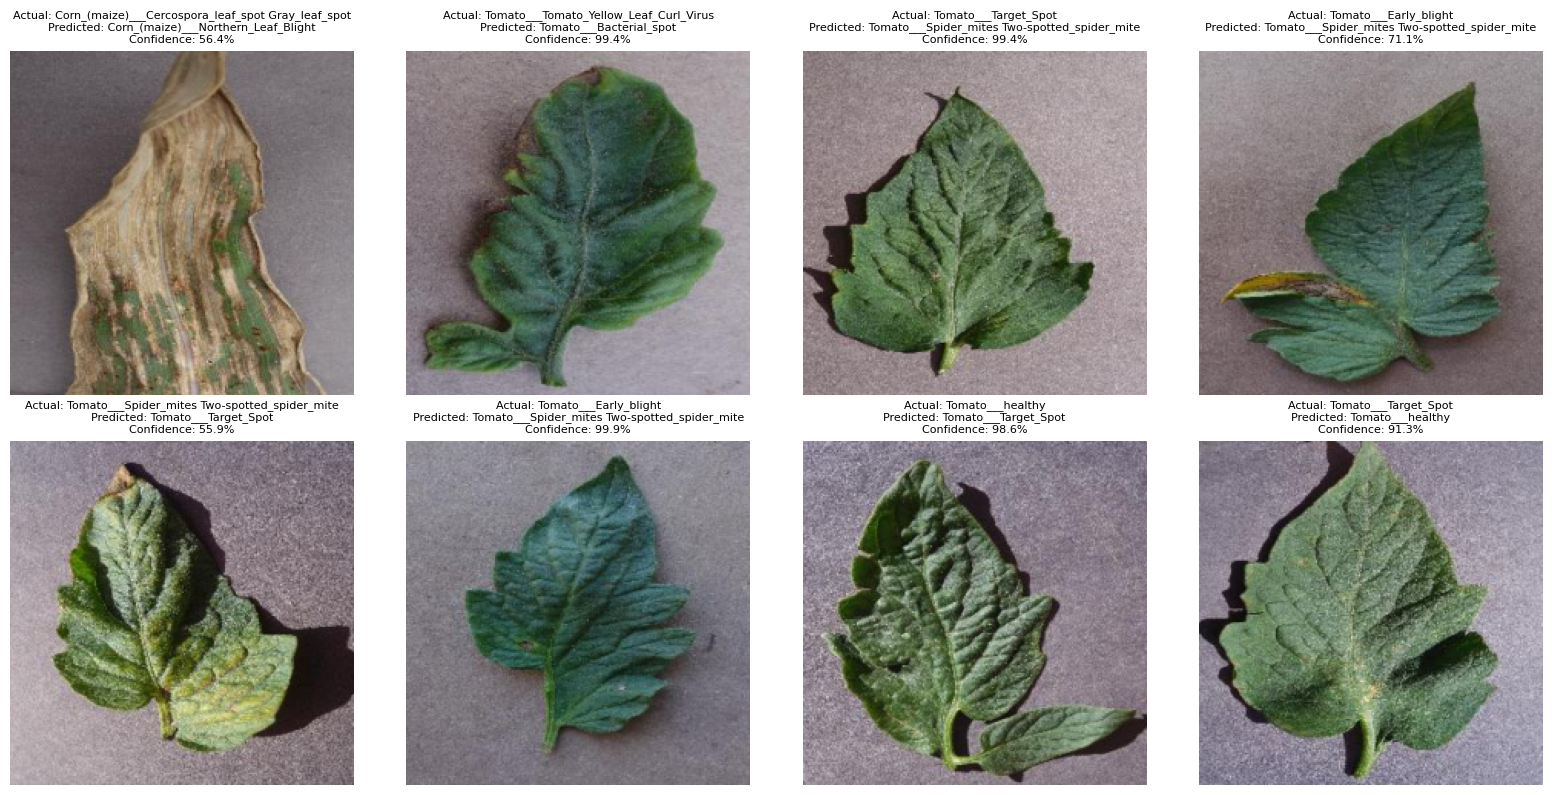

In [28]:

import matplotlib.pyplot as plt
import torch

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

count = min(8, len(wrong_images))

if count == 0:
    print("No misclassified images found in this validation run.")
else:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i in range(count):
        image = wrong_images[i] * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        axes[i].imshow(image)
        axes[i].set_title(
            f"Actual: {dataset.classes[wrong_labels[i]]}\n"
            f"Predicted: {dataset.classes[wrong_predictions[i]]}\n"
            f"Confidence: {wrong_confidences[i]:.1%}",
            fontsize=8
        )
        axes[i].axis("off")

    for i in range(count, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


In [29]:

from PIL import Image
import torch
from torchvision import transforms

# Must match the preprocessing used during training
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_leaf(image, model, class_names, device):
    """
    image: PIL Image
    Returns predicted class, confidence, and top-3 predictions.
    """
    image = image.convert("RGB")
    input_tensor = inference_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]

    top_probabilities, top_indices = torch.topk(
        probabilities, k=min(3, len(class_names))
    )

    top_predictions = [
        {
            "disease": class_names[index.item()],
            "confidence": probability.item()
        }
        for probability, index in zip(top_probabilities, top_indices)
    ]

    return {
        "predicted_disease": top_predictions[0]["disease"],
        "confidence": top_predictions[0]["confidence"],
        "top_3": top_predictions
    }

print("Leaf prediction function created successfully!")


Leaf prediction function created successfully!


Saving keli.jpeg to keli.jpeg


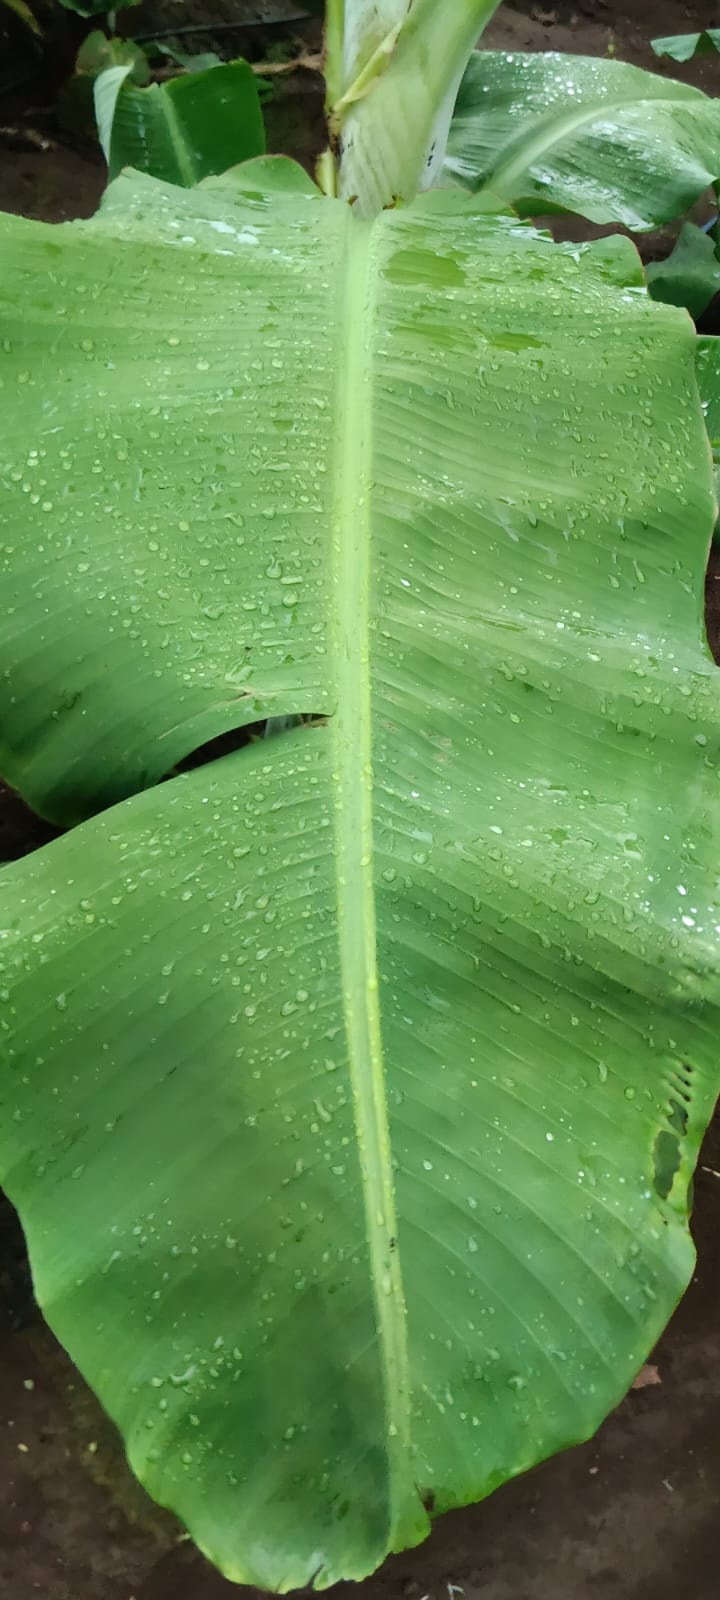


Predicted class: Tomato___Late_blight
Model confidence: 47.30%

Top 3 predictions:
- Tomato___Late_blight: 47.30%
- Corn_(maize)___healthy: 40.80%
- Tomato___Early_blight: 10.79%


In [30]:

from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    display(image)

    result = predict_leaf(
        image, model, dataset.classes, device
    )

    print("\nPredicted class:", result["predicted_disease"])
    print(f"Model confidence: {result['confidence']:.2%}")

    print("\nTop 3 predictions:")
    for item in result["top_3"]:
        print(
            f"- {item['disease']}: "
            f"{item['confidence']:.2%}"
        )


In [31]:

!pip -q install pymupdf


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 42.2 MB/s eta 0:00:00


In [33]:

result = predict_leaf(
    image,
    model,
    dataset.classes,
    device
)

print("Predicted class:", result["predicted_disease"])
print(f"Model confidence: {result['confidence']:.2%}")

print("\nTop 3 predictions:")
for item in result["top_3"]:
    print(f"- {item['disease']}: {item['confidence']:.2%}")


Predicted class: Tomato___Late_blight
Model confidence: 47.30%

Top 3 predictions:
- Tomato___Late_blight: 47.30%
- Corn_(maize)___healthy: 40.80%
- Tomato___Early_blight: 10.79%


In [34]:

from pathlib import Path

root = Path("/content/drive/MyDrive/AgriDoctor_AI")

for folder in ["data", "models", "outputs"]:
    path = root / folder
    print(f"\n{folder.upper()}")

    if path.exists():
        for item in sorted(path.iterdir()):
            print(" -", item.name)
    else:
        print("Folder does not exist yet.")



DATA
 - PlantVillage
 - PlantVillage_38
 - PlantVillage_Clean

MODELS
 - class_names.json
 - resnet18_baseline.pth
 - resnet18_crop_disease.pth
 - resnet18_finetuned.pth

OUTPUTS
 - normalized_confusion_matrix.png


In [35]:

from pathlib import Path
import os

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
EXPANDED_DIR = PROJECT_DIR / "data" / "AgriDoctor_Expanded"

EXPANDED_DIR.mkdir(parents=True, exist_ok=True)

for name in ["banana", "rice", "maize", "sugarcane"]:
    (EXPANDED_DIR / name).mkdir(exist_ok=True)

print("Expanded dataset folders created:")
for path in sorted(EXPANDED_DIR.iterdir()):
    print("-", path.name)

print("\nExisting models preserved:")
for path in sorted((PROJECT_DIR / "models").glob("*.pth")):
    print("-", path.name)


Expanded dataset folders created:
- banana
- maize
- rice
- sugarcane

Existing models preserved:
- resnet18_baseline.pth
- resnet18_crop_disease.pth
- resnet18_finetuned.pth


In [36]:

import requests

api_url = "https://zenodo.org/api/records/7670326"

response = requests.get(api_url, timeout=30)
response.raise_for_status()

metadata = response.json()

print("Dataset:", metadata["metadata"]["title"])
print("\nAvailable files:")

total_bytes = 0

for item in metadata.get("files", []):
    name = item["key"]
    size = item["size"]
    total_bytes += size

    print(f"{name}: {size / (1024**3):.2f} GB")

print(f"\nTotal archive size: {total_bytes / (1024**3):.2f} GB")
print("Metadata inspection completed.")


Dataset: Banana Imagery Dataset - Tanzania

Available files:
HEALTHY-2.zip: 2.11 GB
HEALTHY-3.zip: 2.42 GB
HEALTHY-1.zip: 1.85 GB
BLACK SIGATOKA-3.zip: 4.70 GB
BLACK SIGATOKA-1.zip: 3.48 GB
FUSARIUM WILT-3.zip: 6.72 GB
FUSARIUM WILT-2.zip: 4.62 GB
FUSARIUM WILT-1.zip: 2.90 GB
BLACK SIGATOKA-2.zip: 3.10 GB

Total archive size: 31.91 GB
Metadata inspection completed.


In [37]:

!pip -q install huggingface_hub

from pathlib import Path
from huggingface_hub import snapshot_download
import os

BANANA_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/raw"
)
BANANA_DIR.mkdir(parents=True, exist_ok=True)

dataset_path = snapshot_download(
    repo_id="Project-AgML/banana_leaf_disease_classification",
    repo_type="dataset",
    local_dir=str(BANANA_DIR)
)

print("Download completed!")
print("Dataset location:", dataset_path)

print("\nDownloaded files:")
for root, dirs, files in os.walk(dataset_path):
    dirs[:] = [d for d in dirs if d != ".git"]
    for filename in files[:10]:
        print(os.path.relpath(
            os.path.join(root, filename), dataset_path
        ))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Download completed!
Dataset location: /content/drive/MyDrive/AgriDoctor_AI/data/AgriDoctor_Expanded/banana/raw

Downloaded files:
README.md
.gitattributes
.cache/huggingface/CACHEDIR.TAG
.cache/huggingface/.gitignore
.cache/huggingface/trees/90333badcfbd1f843d55d40eb7388cd6ad6deee7.json
.cache/huggingface/download/README.md.lock
.cache/huggingface/download/.gitattributes.lock
.cache/huggingface/download/README.md.metadata
.cache/huggingface/download/.gitattributes.metadata
.cache/huggingface/download/data/train-00000-of-00001.parquet.lock
.cache/huggingface/download/data/train-00000-of-00001.parquet.metadata
data/train-00000-of-00001.parquet


In [38]:

!pip -q install pandas pyarrow pillow

from pathlib import Path
import pandas as pd

BANANA_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/raw"
)

parquet_path = BANANA_DIR / "data" / "train-00000-of-00001.parquet"

df = pd.read_parquet(parquet_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 3 rows:")
display(df.head(3))

print("\nDataset information:")
df.info()


Dataset shape: (1288, 2)

Columns:
['image', 'label']

First 3 rows:


,image,label
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,2
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,2
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,2



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1288 entries, 0 to 1287
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   image   1288 non-null   object
 1   label   1288 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 20.3+ KB


In [39]:

from collections import Counter
import json
from pathlib import Path

print("Label counts:")
print(df["label"].value_counts().sort_index())

readme_path = BANANA_DIR / "README.md"
readme = readme_path.read_text(encoding="utf-8")

print("\nDataset README (first 5000 characters):")
print(readme[:5000])


Label counts:
label
0    154
1    320
2    814
Name: count, dtype: int64

Dataset README (first 5000 characters):
---
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
license: cc-by-4.0
task_categories:
- image-classification
size_categories:
- 1K<n<10K
dataset_info:
  features:
  - name: image
    dtype: image
  - name: label
    dtype:
      class_label:
        names:
          '0': healthy
          '1': segatoka
          '2': xamthomonas
  splits:
  - name: train
    num_bytes: 6672019
    num_examples: 1288
  download_size: 6920645
  dataset_size: 6672019
---

# Banana Leaf Disease Classification

A dataset for disease classification of Banana Leaves. The dataset contains 1,288 images across 3 classes: healthy, segatoka, xamthomonas.  
Images per class:
- healthy: 154
- segatoka: 320
- xamthomonas: 814

This dataset is indexed on https://project-agml.github.io/ as part of the AgML python library.

## Citation

```bibtex
@article{genet2024siga

In [40]:

from pathlib import Path
from PIL import Image
from io import BytesIO
import pandas as pd

BANANA_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana"
)

IMAGE_DIR = BANANA_DIR / "images"

label_names = {
    0: "healthy",
    1: "sigatoka",
    2: "xanthomonas"
}

for class_name in label_names.values():
    (IMAGE_DIR / class_name).mkdir(parents=True, exist_ok=True)

saved = {name: 0 for name in label_names.values()}
failed = 0

for index, row in df.iterrows():
    try:
        label = int(row["label"])
        class_name = label_names[label]

        image_bytes = row["image"]["bytes"]
        image = Image.open(BytesIO(image_bytes)).convert("RGB")

        output_path = IMAGE_DIR / class_name / f"banana_{index:05d}.jpg"
        image.save(output_path, quality=95)

        saved[class_name] += 1

    except Exception as exc:
        failed += 1
        print(f"Could not process row {index}: {exc}")

print("\nExtraction complete")
print("Saved images by class:")
for class_name, count in saved.items():
    print(f"{class_name}: {count}")

print("Failed images:", failed)
print("Output folder:", IMAGE_DIR)



Extraction complete
Saved images by class:
healthy: 154
sigatoka: 320
xanthomonas: 814
Failed images: 0
Output folder: /content/drive/MyDrive/AgriDoctor_AI/data/AgriDoctor_Expanded/banana/images


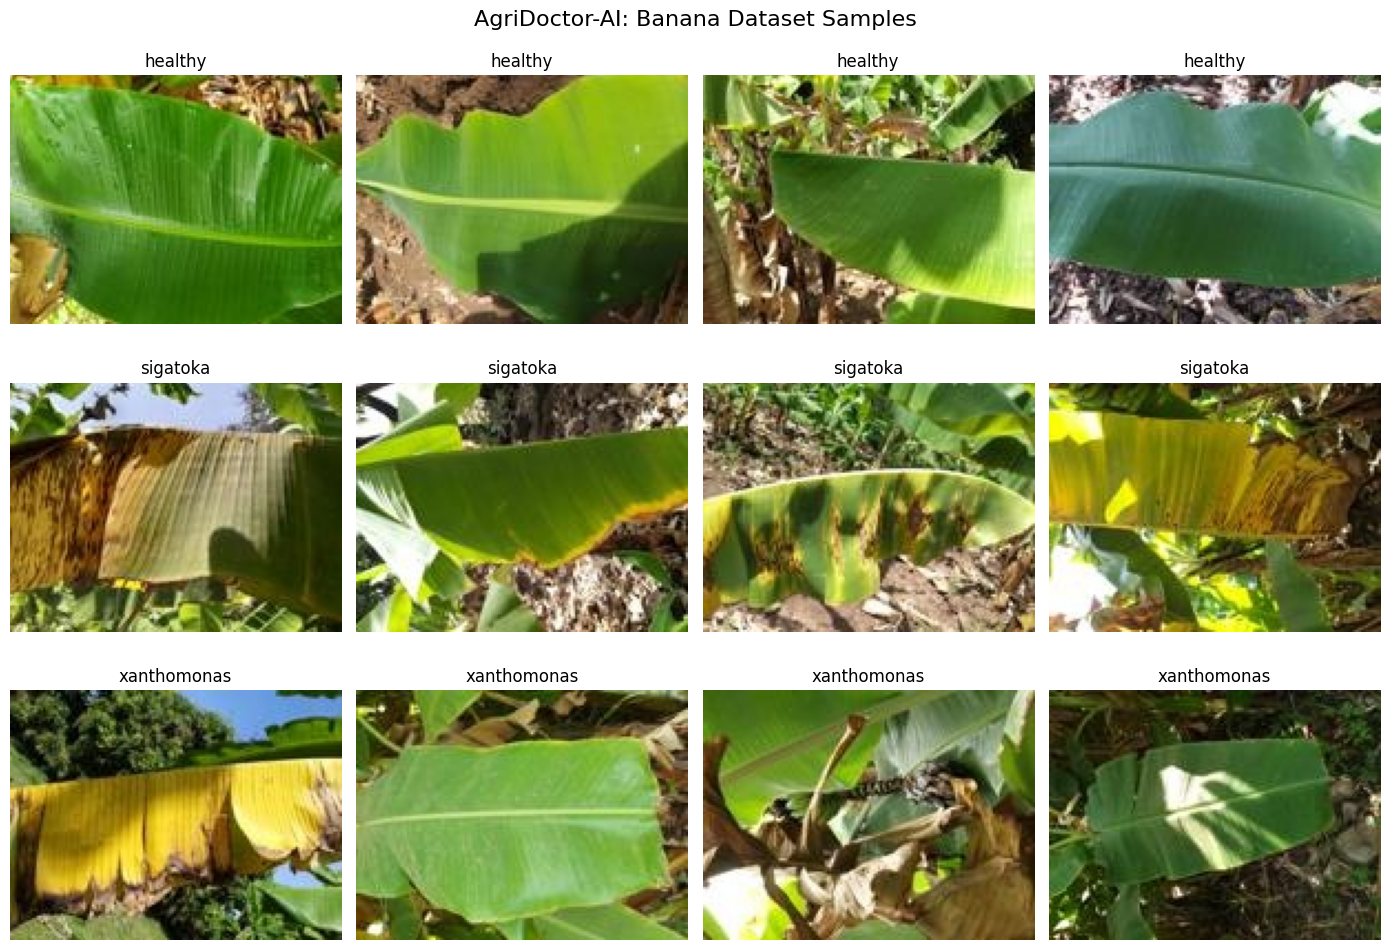

In [41]:

import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

IMAGE_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/images"
)

random.seed(42)
classes = ["healthy", "sigatoka", "xanthomonas"]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, class_name in enumerate(classes):
    files = list((IMAGE_DIR / class_name).glob("*.jpg"))
    samples = random.sample(files, min(4, len(files)))

    for col in range(4):
        ax = axes[row, col]

        if col < len(samples):
            image = Image.open(samples[col]).convert("RGB")
            ax.imshow(image)
            ax.set_title(class_name)
        ax.axis("off")

plt.suptitle("AgriDoctor-AI: Banana Dataset Samples", fontsize=16)
plt.tight_layout()
plt.show()


In [42]:

from pathlib import Path
from sklearn.model_selection import train_test_split
import shutil
import pandas as pd

SOURCE_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/images"
)

SPLIT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/split"
)

classes = ["healthy", "sigatoka", "xanthomonas"]

# Collect image paths and their labels
records = []

for class_name in classes:
    for image_path in (SOURCE_DIR / class_name).glob("*.jpg"):
        records.append({
            "image_path": str(image_path),
            "label": class_name
        })

df_banana = pd.DataFrame(records)

# Split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df_banana,
    test_size=0.30,
    stratify=df_banana["label"],
    random_state=42
)

# Split temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Create output directories and copy images
for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for _, row in split_df.iterrows():
        destination_dir = SPLIT_DIR / split_name / row["label"]
        destination_dir.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            row["image_path"],
            destination_dir / Path(row["image_path"]).name
        )

print("Dataset split complete!")
print("Total images:", len(df_banana))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClass counts in each split:")
for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    print(f"\n{split_name.upper()}")
    print(split_df["label"].value_counts().sort_index())

print("\nSaved to:", SPLIT_DIR)


Dataset split complete!
Total images: 1288
Training images: 901
Validation images: 193
Testing images: 194

Class counts in each split:

TRAIN
label
healthy        108
sigatoka       224
xanthomonas    569
Name: count, dtype: int64

VAL
label
healthy         23
sigatoka        48
xanthomonas    122
Name: count, dtype: int64

TEST
label
healthy         23
sigatoka        48
xanthomonas    123
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/AgriDoctor_AI/data/AgriDoctor_Expanded/banana/split


In [44]:

from pathlib import Path

SPLIT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/split"
)

classes = ["healthy", "sigatoka", "xanthomonas"]
splits = ["train", "val", "test"]

total = 0

for split_name in splits:
    print(f"\n{split_name.upper()}")
    split_total = 0

    for class_name in classes:
        folder = SPLIT_DIR / split_name / class_name
        count = len(list(folder.glob("*.jpg"))) if folder.exists() else 0
        print(f"  {class_name}: {count}")
        split_total += count

    print("  Total:", split_total)
    total += split_total

print("\nTOTAL IMAGES:", total)

if total == 1288:
    print("SUCCESS: All 1,288 images are accounted for.")
else:
    print("WARNING: Expected 1,288 images. Check the split folders.")



TRAIN
  healthy: 108
  sigatoka: 224
  xanthomonas: 569
  Total: 901

VAL
  healthy: 23
  sigatoka: 48
  xanthomonas: 122
  Total: 193

TEST
  healthy: 23
  sigatoka: 48
  xanthomonas: 123
  Total: 194

TOTAL IMAGES: 1288
SUCCESS: All 1,288 images are accounted for.


In [43]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

SPLIT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/split"
)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Preprocessing for ResNet18
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    SPLIT_DIR / "train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    SPLIT_DIR / "val",
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    SPLIT_DIR / "test",
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("\nClass mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

# Verify one batch
images, labels = next(iter(train_loader))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Device: cuda

Class mapping: {'healthy': 0, 'sigatoka': 1, 'xanthomonas': 2}
Training images: 901
Validation images: 193
Testing images: 194

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])


In [45]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet18
try:
    weights = models.ResNet18_Weights.DEFAULT
    banana_model = models.resnet18(weights=weights)
    print("Loaded pretrained ResNet18 weights.")
except Exception as exc:
    print("Could not load pretrained weights:", exc)
    print("Trying to load ResNet18 without pretrained weights.")
    banana_model = models.resnet18(weights=None)

# Freeze the earlier layers
for param in banana_model.parameters():
    param.requires_grad = False

# Replace the final layer for 3 banana classes
num_features = banana_model.fc.in_features
banana_model.fc = nn.Linear(num_features, 3)

# Train the final layer
for param in banana_model.fc.parameters():
    param.requires_grad = True

banana_model = banana_model.to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    banana_model.fc.parameters(),
    lr=0.001
)

print("\nModel configured successfully!")
print("Classes:", train_dataset.classes)
print("Output classes:", banana_model.fc.out_features)
print("Trainable parameters:", sum(
    p.numel() for p in banana_model.parameters() if p.requires_grad
))
print("Device:", device)


Loaded pretrained ResNet18 weights.

Model configured successfully!
Classes: ['healthy', 'sigatoka', 'xanthomonas']
Output classes: 3
Trainable parameters: 1539
Device: cuda


In [46]:

import copy
import torch
import torch.nn as nn
from collections import Counter
from pathlib import Path

# Calculate class weights from training labels
class_counts = Counter(train_dataset.targets)

class_weights = torch.tensor(
    [
        len(train_dataset) / (3 * class_counts[i])
        for i in range(3)
    ],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

# Save the best model
MODEL_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "banana_resnet18_best.pth"
)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

epochs = 5
best_val_accuracy = 0.0
best_state = copy.deepcopy(banana_model.state_dict())

for epoch in range(epochs):
    # Training
    banana_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = banana_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    # Validation
    banana_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = banana_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total
    val_loss /= val_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = copy.deepcopy(banana_model.state_dict())

# Restore and save the best validation model
banana_model.load_state_dict(best_state)
torch.save(banana_model.state_dict(), MODEL_PATH)

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")
print("Best model saved to:", MODEL_PATH)


Epoch 1/5 | Train Loss: 1.0047 | Train Acc: 45.39% | Val Loss: 0.8277 | Val Acc: 64.25%
Epoch 2/5 | Train Loss: 0.8411 | Train Acc: 57.60% | Val Loss: 0.8284 | Val Acc: 63.21%
Epoch 3/5 | Train Loss: 0.7174 | Train Acc: 68.04% | Val Loss: 0.7437 | Val Acc: 68.39%
Epoch 4/5 | Train Loss: 0.6608 | Train Acc: 67.70% | Val Loss: 0.7272 | Val Acc: 66.84%
Epoch 5/5 | Train Loss: 0.6261 | Train Acc: 69.59% | Val Loss: 0.7227 | Val Acc: 66.84%

Training complete.
Best validation accuracy: 68.39%
Best model saved to: /content/drive/MyDrive/AgriDoctor_AI/models/banana_resnet18_best.pth


In [47]:

import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

banana_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = banana_model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

# Overall test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy:.2%}")

# Precision, recall, and F1-score for every class
print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(test_dataset.classes))),
        target_names=test_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        all_labels,
        all_predictions,
        labels=list(range(len(test_dataset.classes)))
    )
)
print("\nClass order:", test_dataset.classes)


Test Accuracy: 68.56%

Classification Report:
              precision    recall  f1-score   support

     healthy     0.4118    0.6087    0.4912        23
    sigatoka     0.5932    0.7292    0.6542        48
 xanthomonas     0.8317    0.6829    0.7500       123

    accuracy                         0.6856       194
   macro avg     0.6122    0.6736    0.6318       194
weighted avg     0.7229    0.6856    0.6956       194


Confusion Matrix:
[[14  4  5]
 [ 1 35 12]
 [19 20 84]]

Class order: ['healthy', 'sigatoka', 'xanthomonas']


In [48]:

import torch
import torch.nn as nn
import copy

# Start from the best model saved during the first training run
banana_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/AgriDoctor_AI/models/"
        "banana_resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

# Freeze all parameters
for param in banana_model.parameters():
    param.requires_grad = False

# Unfreeze deeper feature layers and classifier
for param in banana_model.layer4.parameters():
    param.requires_grad = True

for param in banana_model.fc.parameters():
    param.requires_grad = True

# Rebuild optimizer for the newly trainable layers
optimizer = torch.optim.AdamW(
    [
        {"params": banana_model.layer4.parameters(), "lr": 1e-5},
        {"params": banana_model.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

print("Fine-tuning configured.")
print("Trainable layers: layer4 and fc")
print("Learning rates: layer4=1e-5, fc=1e-4")
print("Device:", device)


Fine-tuning configured.
Trainable layers: layer4 and fc
Learning rates: layer4=1e-5, fc=1e-4
Device: cuda


In [49]:

import copy
import torch
from pathlib import Path
from sklearn.metrics import recall_score

MODEL_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "banana_resnet18_finetuned_best.pth"
)

best_val_accuracy = 0.0
best_state = copy.deepcopy(banana_model.state_dict())

for epoch in range(5):
    # Training
    banana_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = banana_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    # Validation
    banana_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = banana_model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)

            val_loss += loss.item() * labels.size(0)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

            val_labels.extend(labels.cpu().tolist())
            val_predictions.extend(predictions.cpu().tolist())

    train_loss /= train_total
    train_accuracy = train_correct / train_total
    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # Class index 0 is healthy
    healthy_recall = recall_score(
        val_labels,
        val_predictions,
        labels=[0],
        average=None,
        zero_division=0
    )[0]

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%} | "
        f"Healthy Recall: {healthy_recall:.2%}"
    )

    # Keep the best validation-accuracy checkpoint
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = copy.deepcopy(banana_model.state_dict())

banana_model.load_state_dict(best_state)
torch.save(banana_model.state_dict(), MODEL_PATH)

print("\nFine-tuning complete.")
print(f"Best validation accuracy: {best_val_accuracy:.2%}")
print("Saved model:", MODEL_PATH)


Epoch 1/5 | Train Loss: 0.6178 | Train Acc: 71.37% | Val Loss: 0.6549 | Val Acc: 73.06% | Healthy Recall: 69.57%
Epoch 2/5 | Train Loss: 0.5468 | Train Acc: 76.36% | Val Loss: 0.6196 | Val Acc: 75.13% | Healthy Recall: 73.91%
Epoch 3/5 | Train Loss: 0.4777 | Train Acc: 78.14% | Val Loss: 0.5790 | Val Acc: 75.65% | Healthy Recall: 69.57%
Epoch 4/5 | Train Loss: 0.4595 | Train Acc: 78.47% | Val Loss: 0.5671 | Val Acc: 75.65% | Healthy Recall: 69.57%
Epoch 5/5 | Train Loss: 0.4094 | Train Acc: 80.36% | Val Loss: 0.5140 | Val Acc: 77.20% | Healthy Recall: 69.57%

Fine-tuning complete.
Best validation accuracy: 77.20%
Saved model: /content/drive/MyDrive/AgriDoctor_AI/models/banana_resnet18_finetuned_best.pth


In [50]:

import torch
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

MODEL_PATH = (
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "banana_resnet18_finetuned_best.pth"
)

# Load the best validation checkpoint
banana_model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
banana_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = banana_model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

print(f"Fine-tuned Test Accuracy: {accuracy_score(all_labels, all_predictions):.2%}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1, 2],
    target_names=test_dataset.classes,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions, labels=[0, 1, 2]))
print("\nClass order:", test_dataset.classes)


Fine-tuned Test Accuracy: 81.96%

Classification Report:
              precision    recall  f1-score   support

     healthy     0.6000    0.7826    0.6792        23
    sigatoka     0.7647    0.8125    0.7879        48
 xanthomonas     0.9027    0.8293    0.8644       123

    accuracy                         0.8196       194
   macro avg     0.7558    0.8081    0.7772       194
weighted avg     0.8326    0.8196    0.8235       194


Confusion Matrix:
[[ 18   2   3]
 [  1  39   8]
 [ 11  10 102]]

Class order: ['healthy', 'sigatoka', 'xanthomonas']


In [51]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/outputs"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class_names = test_dataset.classes

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_path = OUTPUT_DIR / "banana_finetuned_classification_report.csv"
report_df.to_csv(report_path, index=True)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{name}" for name in class_names],
    columns=[f"Predicted_{name}" for name in class_names]
)

cm_path = OUTPUT_DIR / "banana_finetuned_confusion_matrix.csv"
cm_df.to_csv(cm_path, index=True)

print("Evaluation files saved:")
print(report_path)
print(cm_path)
print("\nConfusion matrix:")
display(cm_df)


Evaluation files saved:
/content/drive/MyDrive/AgriDoctor_AI/outputs/banana_finetuned_classification_report.csv
/content/drive/MyDrive/AgriDoctor_AI/outputs/banana_finetuned_confusion_matrix.csv

Confusion matrix:


,Predicted_healthy,Predicted_sigatoka,Predicted_xanthomonas
Actual_healthy,18,2,3
Actual_sigatoka,1,39,8
Actual_xanthomonas,11,10,102


In [52]:

from pathlib import Path
from collections import defaultdict
import hashlib

SPLIT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/data/"
    "AgriDoctor_Expanded/banana/split"
)

hash_locations = defaultdict(list)

for split_name in ["train", "val", "test"]:
    for image_path in (SPLIT_DIR / split_name).rglob("*.jpg"):
        with open(image_path, "rb") as f:
            image_hash = hashlib.sha256(f.read()).hexdigest()

        hash_locations[image_hash].append(
            (split_name, str(image_path))
        )

duplicates = {
    image_hash: locations
    for image_hash, locations in hash_locations.items()
    if len(locations) > 1
}

cross_split_duplicates = {
    image_hash: locations
    for image_hash, locations in duplicates.items()
    if len(set(split for split, _ in locations)) > 1
}

print("Unique image hashes:", len(hash_locations))
print("Hashes appearing more than once:", len(duplicates))
print("Duplicates shared across splits:", len(cross_split_duplicates))

if cross_split_duplicates:
    print("\nExamples of cross-split duplicates:")
    for locations in list(cross_split_duplicates.values())[:5]:
        for split_name, path in locations:
            print(split_name, "->", path)
        print()
else:
    print("\nNo exact duplicates found across the splits.")


Unique image hashes: 1288
Hashes appearing more than once: 0
Duplicates shared across splits: 0

No exact duplicates found across the splits.


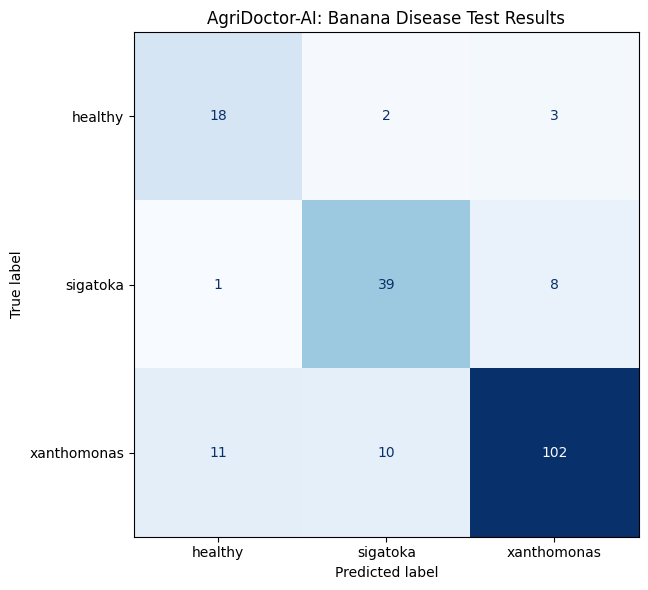

Confusion matrix saved to: /content/drive/MyDrive/AgriDoctor_AI/outputs/banana_finetuned_confusion_matrix.png


In [53]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from pathlib import Path

class_names = test_dataset.classes

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    values_format="d",
    cmap="Blues",
    colorbar=False
)

plt.title("AgriDoctor-AI: Banana Disease Test Results")
plt.tight_layout()

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/outputs/"
    "banana_finetuned_confusion_matrix.png"
)

plt.savefig(OUTPUT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", OUTPUT_PATH)


In [54]:

import torch
from PIL import Image
from torchvision import transforms
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "banana_resnet18_finetuned_best.pth"
)

class_names = test_dataset.classes

inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load the saved model checkpoint
banana_model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
banana_model.eval()

def predict_banana_leaf(image_path):
    image = Image.open(image_path).convert("RGB")
    input_tensor = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = banana_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]

    ranked = torch.argsort(probabilities, descending=True)

    results = [
        {
            "class": class_names[index.item()],
            "confidence": round(probabilities[index].item() * 100, 2)
        }
        for index in ranked
    ]

    return results

print("Banana prediction function ready!")
print("Supported classes:", class_names)


Banana prediction function ready!
Supported classes: ['healthy', 'sigatoka', 'xanthomonas']


In [55]:

!apt-get -qq install -y poppler-utils
!pip -q install pdf2image


E: Failed to fetch http://security.ubuntu.com/ubuntu/pool/main/p/poppler/poppler-utils_24.02.0-1ubuntu9.9_amd64.deb  404  Not Found [IP: 91.189.92.22 80]
E: Unable to fetch some archives, maybe run apt-get update or try with --fix-missing?


In [60]:

!pip -q install pymupdf


In [63]:

predictions = predict_banana_leaf("banana_leaf_converted.png")

print("Top predictions:")
for item in predictions:
    print(f"{item['class']}: {item['confidence']:.2f}%")


FileNotFoundError: [Errno 2] No such file or directory: 'banana_leaf_converted.png'

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

image = Image.open("banana_leaf_converted.png").convert("RGB")

print("Image dimensions:", image.size)

plt.figure(figsize=(8, 7))
plt.imshow(image)
plt.title("Image Actually Sent to the Model")
plt.axis("off")
plt.show()


In [ ]:

def safe_banana_prediction(image_path, threshold=0.70, margin=0.15):
    """
    Display a model prediction only when its score and
    separation from the second prediction meet our thresholds.

    These are provisional safeguards, not clinically or
    agriculturally validated confidence thresholds.
    """
    predictions = predict_banana_leaf(image_path)

    top = predictions[0]
    second = predictions[1]

    top_score = top["confidence"] / 100
    second_score = second["confidence"] / 100
    score_margin = top_score - second_score

    print("Model scores:")
    for item in predictions:
        print(f"  {item['class']}: {item['confidence']:.2f}%")

    if top_score < threshold or score_margin < margin:
        print("\n⚠️ UNCERTAIN RESULT")
        print("The model cannot provide a sufficiently clear prediction.")
        print("Please obtain confirmation from an agricultural expert.")
        return {
            "status": "uncertain",
            "predictions": predictions
        }

    print(f"\nProvisional model prediction: {top['class']}")
    print("This is not a confirmed diagnosis.")
    return {
        "status": "model_prediction",
        "predicted_class": top["class"],
        "score": top["confidence"],
        "predictions": predictions
    }

result = safe_banana_prediction("banana_leaf_converted.png")


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI"
)

MODEL_REGISTRY = {
    "banana": {
        "model_path": PROJECT_DIR / "models" /
                     "banana_resnet18_finetuned_best.pth",
        "classes": ["healthy", "sigatoka", "xanthomonas"],
        "status": "experimental",
    },
    "plantvillage": {
        "model_path": PROJECT_DIR / "models" /
                     "resnet18_finetuned.pth",
        "status": "existing_38_class_model",
    },
}

for crop, details in MODEL_REGISTRY.items():
    print(f"\nCrop/model: {crop}")
    print("Checkpoint:", details["model_path"])
    print("Checkpoint exists:", details["model_path"].exists())
    print("Status:", details["status"])

print("\nBanana classes:", MODEL_REGISTRY["banana"]["classes"])
print("\nRegistry created.")


In [ ]:

def predict_by_crop(image_path, crop_name):
    """
    Route an image to the selected crop's model.
    Banana predictions use the experimental banana model.
    PlantVillage predictions require the existing model's
    own prediction function and class mapping.
    """

    crop_name = crop_name.strip().lower()

    if crop_name == "banana":
        return safe_banana_prediction(image_path)

    elif crop_name == "plantvillage":
        return {
            "status": "not_connected",
            "message": (
                "The PlantVillage model needs its exact saved "
                "class mapping and prediction function connected."
            )
        }

    else:
        return {
            "status": "unsupported_crop",
            "message": (
                f"Crop '{crop_name}' is not supported yet. "
                "Please choose a supported crop."
            )
        }


# Test the router with the banana image
result = predict_by_crop(
    "banana_leaf_converted.png",
    "banana"
)

print("\nRouter result:")
print(result)


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI"
)

paths_to_check = [
    PROJECT_DIR / "models" / "resnet18_finetuned.pth",
    PROJECT_DIR / "models" / "resnet18_baseline.pth",
    PROJECT_DIR / "data",
]

for path in paths_to_check:
    print(f"{path.name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("\nChecking for saved class-name files:")

for path in (PROJECT_DIR / "models").glob("*"):
    print(path.name)


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI"
)

# Search likely PlantVillage dataset locations
search_roots = [
    PROJECT_DIR / "data",
    Path("/content/drive/MyDrive"),
]

found = set()

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_dir():
            continue

        name = path.name.lower()

        if name in {
            "plantvillage",
            "plantvillage_clean",
            "plantvillage_38",
        }:
            found.add(path)

for path in sorted(found):
    print(f"\nDataset folder: {path}")

    class_folders = sorted(
        p.name for p in path.iterdir()
        if p.is_dir() and not p.name.startswith(".")
    )

    print("Number of immediate subfolders:", len(class_folders))
    print("First 10 folders:", class_folders[:10])

if not found:
    print(
        "No named PlantVillage dataset folder found. "
        "We will check the training notebook or saved metadata next."
    )


In [ ]:

from pathlib import Path
from torchvision import datasets

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI"
)

DATASET_DIR = PROJECT_DIR / "data" / "PlantVillage_38"

# ImageFolder sorts class names alphabetically by default
dataset_check = datasets.ImageFolder(DATASET_DIR)
plantvillage_classes = dataset_check.classes

print("Number of classes:", len(plantvillage_classes))
print("\nExact class mapping:")

for index, class_name in enumerate(plantvillage_classes):
    print(f"{index}: {class_name}")

if len(plantvillage_classes) == 38:
    print("\nSUCCESS: Found 38 classes.")
else:
    print("\nWARNING: Expected 38 classes.")


In [ ]:

import torch
from pathlib import Path
from torchvision import models
import torch.nn as nn

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgriDoctor_AI"
)

MODEL_PATH = PROJECT_DIR / "models" / "resnet18_finetuned.pth"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint).__name__)

# Rebuild the ResNet18 architecture for inspection
plantvillage_model = models.resnet18(weights=None)
plantvillage_model.fc = nn.Linear(
    plantvillage_model.fc.in_features,
    38
)

try:
    plantvillage_model.load_state_dict(checkpoint, strict=True)
    print("SUCCESS: Checkpoint matches ResNet18 with 38 outputs.")
except RuntimeError as exc:
    print("Checkpoint did not match the expected architecture.")
    print(str(exc)[:2000])


In [ ]:

import torch
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "resnet18_finetuned.pth"
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    for key in list(checkpoint.keys())[:30]:
        value = checkpoint[key]
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif torch.is_tensor(value):
            print(f"{key}: tensor shape {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")

    print("\nFirst 20 keys:")
    print(list(checkpoint.keys())[:20])


In [ ]:

import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/AgriDoctor_AI/models/"
    "resnet18_finetuned.pth"
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

# Use the metadata stored with the trained checkpoint
plantvillage_classes = checkpoint["class_names"]
num_classes = checkpoint["num_classes"]

print("Saved number of classes:", num_classes)
print("Number of saved class names:", len(plantvillage_classes))
print("\nSaved class mapping:")

for index, name in enumerate(plantvillage_classes):
    print(f"{index}: {name}")

# Rebuild the architecture and load the nested state dictionary
plantvillage_model = models.resnet18(weights=None)
plantvillage_model.fc = nn.Linear(
    plantvillage_model.fc.in_features,
    num_classes
)

plantvillage_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plantvillage_model = plantvillage_model.to(device)
plantvillage_model.eval()

print("\nSUCCESS: PlantVillage model loaded.")
print("Device:", device)
print("Output classes:", plantvillage_model.fc.out_features)


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

app_code = r'''
import streamlit as st

st.set_page_config(
    page_title="AgriDoctor AI",
    page_icon="🌱",
    layout="centered"
)

st.title("🌱 AgriDoctor AI")
st.subheader("AI-powered crop leaf health assistant")
st.write(
    "Upload a clear leaf photo to explore a possible disease prediction "
    "and get crop-health guidance."
)

crop = st.selectbox(
    "Choose the crop",
    ["Banana", "PlantVillage-supported crop"]
)

uploaded_file = st.file_uploader(
    "Upload a leaf photo",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    st.image(uploaded_file, caption="Uploaded leaf photo",
             use_container_width=True)

if st.button("🔍 Analyze leaf", type="primary"):
    if uploaded_file is None:
        st.warning("Please upload a leaf photo first.")
    else:
        st.info(
            "Image received. Model connection is the next step."
        )

st.caption(
    "Prototype only: predictions may be incorrect. "
    "Confirm disease and treatment with a qualified agricultural expert."
)
'''

APP_PATH.write_text(app_code, encoding="utf-8")

print("Streamlit app created:", APP_PATH)
print("File size:", APP_PATH.stat().st_size, "bytes")


In [ ]:

%pip install -q streamlit


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

app_code = r'''
import streamlit as st
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from pathlib import Path

st.set_page_config(page_title="AgriDoctor AI", page_icon="🌱")
st.title("🌱 AgriDoctor AI")
st.write("Upload a crop leaf photo for an experimental AI prediction.")

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
MODEL_DIR = PROJECT_DIR / "models"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@st.cache_resource
def load_model(model_path):
    checkpoint = torch.load(
        model_path, map_location=DEVICE, weights_only=True
    )
    classes = checkpoint["class_names"]
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(classes))
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(DEVICE).eval()
    return model, classes

crop = st.selectbox("Select model", [
    "Banana (experimental)",
    "PlantVillage (38 classes)"
])

uploaded_file = st.file_uploader(
    "Upload a leaf image", type=["jpg", "jpeg", "png"]
)

if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded leaf", use_container_width=True)

    if st.button("Analyze leaf", type="primary"):
        if crop == "Banana (experimental)":
            model_path = MODEL_DIR / "banana_resnet18_finetuned_best.pth"
        else:
            model_path = MODEL_DIR / "resnet18_finetuned.pth"

        if not model_path.exists():
            st.error(f"Model file not found: {model_path.name}")
        else:
            try:
                model, classes = load_model(str(model_path))
                tensor = TRANSFORM(image).unsqueeze(0).to(DEVICE)

                with torch.no_grad():
                    probabilities = torch.softmax(model(tensor), dim=1)[0]

                values, indices = torch.topk(
                    probabilities, k=min(3, len(classes))
                )
                top_score = values[0].item()
                second_score = values[1].item() if len(values) > 1 else 0

                st.subheader("Prediction results")
                for score, index in zip(values, indices):
                    st.write(
                        f"**{classes[index.item()].replace('_', ' ')}** "
                        f"— {score.item() * 100:.1f}% model score"
                    )

                if top_score < 0.70 or top_score - second_score < 0.15:
                    st.warning(
                        "Uncertain result. Do not rely on this prediction "
                        "alone to choose treatment."
                    )
                else:
                    st.info(
                        "This is a model prediction, not a confirmed diagnosis. "
                        "Verify with an agricultural expert before treatment."
                    )

            except Exception as error:
                st.error(f"Could not run prediction: {error}")

st.caption(
    "Experimental prototype. The banana model supports three labels; "
    "the PlantVillage model supports only its saved 38 classes. "
    "Performance on real farm photos may differ from test results."
)
'''

APP_PATH.write_text(app_code, encoding="utf-8")
print("Updated app:", APP_PATH)
print("Exists:", APP_PATH.exists())
print("Size:", APP_PATH.stat().st_size, "bytes")


In [ ]:

import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

# Stop an earlier Streamlit process if one exists
subprocess.run(
    "pkill -f 'streamlit run' || true",
    shell=True,
    capture_output=True
)

log_file = open(PROJECT_DIR / "streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process ID:", process.pid)
print("App file exists:", APP_PATH.exists())
print("Log file:", PROJECT_DIR / "streamlit.log")

if process.poll() is None:
    print("Streamlit process is running.")
else:
    print("Streamlit stopped. Check streamlit.log for the error.")
    print((PROJECT_DIR / "streamlit.log").read_text()[-3000:])


In [ ]:

%pip install -q pyngrok


In [ ]:

from pyngrok import ngrok
import os

# Enter your ngrok authentication token in Colab when prompted.
# Get it from https://dashboard.ngrok.com/get-started/your-authtoken
from getpass import getpass

token = getpass("Enter your ngrok auth token: ")
ngrok.set_auth_token(token)

# Create a public tunnel to Streamlit
tunnel = ngrok.connect(8501, "http")
print("🌱 AgriDoctor-AI public URL:", tunnel.public_url)


In [ ]:

import torch
from pathlib import Path

MODEL_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI/models")

for filename in [
    "banana_resnet18_finetuned_best.pth",
    "resnet18_finetuned.pth"
]:
    path = MODEL_DIR / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    if isinstance(checkpoint, dict):
        print("Available keys:", list(checkpoint.keys()))
        for key in ["class_names", "classes", "classes_list",
                    "num_classes", "model_state_dict"]:
            if key in checkpoint:
                value = checkpoint[key]
                if key == "model_state_dict":
                    print(key, "is present")
                else:
                    print(f"{key}:", value)
    else:
        print("Checkpoint type:", type(checkpoint))


In [ ]:

import torch
from pathlib import Path

MODEL_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI/models")

for filename in [
    "banana_resnet18_finetuned_best.pth",
    "resnet18_finetuned.pth"
]:
    path = MODEL_DIR / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("❌ File not found")
        continue

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))

        for key in ["class_names", "classes", "num_classes"]:
            if key in checkpoint:
                print(f"{key}:", checkpoint[key])

        if "model_state_dict" in checkpoint:
            print("Model weights are stored under model_state_dict.")
        elif all(torch.is_tensor(v) for v in checkpoint.values()):
            print("Checkpoint appears to contain model weights directly.")


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

app_code = r'''
import streamlit as st
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from pathlib import Path

st.set_page_config(page_title="AgriDoctor AI", page_icon="🌱")
st.title("🌱 AgriDoctor AI")
st.write("Upload a crop leaf photo for an experimental AI prediction.")

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
MODEL_DIR = PROJECT_DIR / "models"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@st.cache_resource
def load_model(model_path, crop_type):
    checkpoint = torch.load(
        model_path, map_location=DEVICE, weights_only=True
    )

    if not isinstance(checkpoint, dict):
        raise ValueError("Unsupported checkpoint format.")

    # Support checkpoints containing nested weights or raw weights.
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    # Use saved class labels whenever available.
    classes = checkpoint.get("class_names")

    if classes is None:
        classes = checkpoint.get("classes")

    if classes is None and crop_type == "banana":
        classes = ["healthy", "sigatoka", "xanthomonas"]

    if classes is None:
        raise ValueError(
            "This checkpoint does not contain class labels. "
            "We must recover the original training class order before "
            "using this model."
        )

    num_classes = checkpoint.get("num_classes", len(classes))
    if len(classes) != num_classes:
        raise ValueError("Saved class labels do not match num_classes.")

    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model.load_state_dict(state_dict, strict=True)
    model.to(DEVICE).eval()

    return model, classes

crop = st.selectbox(
    "Select model",
    ["Banana (experimental)", "PlantVillage (38 classes)"]
)

uploaded_file = st.file_uploader(
    "Upload a leaf image", type=["jpg", "jpeg", "png"]
)

if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded leaf", use_container_width=True)

    if st.button("Analyze leaf", type="primary"):
        if crop == "Banana (experimental)":
            model_path = MODEL_DIR / "banana_resnet18_finetuned_best.pth"
            crop_type = "banana"
        else:
            model_path = MODEL_DIR / "resnet18_finetuned.pth"
            crop_type = "plantvillage"

        try:
            if not model_path.exists():
                raise FileNotFoundError(f"Missing model: {model_path.name}")

            model, classes = load_model(str(model_path), crop_type)
            tensor = TRANSFORM(image).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                probabilities = torch.softmax(model(tensor), dim=1)[0]

            values, indices = torch.topk(
                probabilities, k=min(3, len(classes))
            )

            st.subheader("Prediction results")
            for score, index in zip(values, indices):
                st.write(
                    f"**{classes[index.item()].replace('_', ' ')}** — "
                    f"{score.item() * 100:.1f}% model score"
                )

            top_score = values[0].item()
            second_score = values[1].item() if len(values) > 1 else 0

            if top_score < 0.70 or top_score - second_score < 0.15:
                st.warning(
                    "Uncertain result. Do not choose treatment based on "
                    "this prediction alone."
                )
            else:
                st.info(
                    "Experimental prediction only. Confirm with an "
                    "agricultural expert before treatment."
                )

        except Exception as error:
            st.error(f"Prediction failed: {error}")

st.caption(
    "Experimental prototype. Real farm photos may differ from training "
    "images. Predictions are not confirmed diagnoses."
)
'''

APP_PATH.write_text(app_code, encoding="utf-8")
print("Updated app.py successfully.")
print("Saved at:", APP_PATH)


In [ ]:

import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")

subprocess.run(
    ["pkill", "-f", "streamlit run"],
    capture_output=True
)

time.sleep(2)

log = open(PROJECT_DIR / "streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(4)
print("Streamlit PID:", process.pid)
print("Running:", process.poll() is None)


In [ ]:

import requests
import subprocess
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")

# Check whether Streamlit responds locally
try:
    response = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=5)
    print("Health status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Local connection failed:", repr(e))

# Inspect the latest Streamlit log
log_path = PROJECT_DIR / "streamlit.log"
if log_path.exists():
    print("\n--- Latest Streamlit log ---")
    print(log_path.read_text(errors="replace")[-4000:])

# Check what is listening on port 8501
result = subprocess.run(
    ["bash", "-lc", "ss -ltnp | grep ':8501' || true"],
    capture_output=True,
    text=True
)
print("\n--- Port 8501 ---")
print(result.stdout or "Nothing is listening on port 8501.")


In [ ]:

from pyngrok import ngrok
import requests

# Close stale tunnels
ngrok.kill()

# Connect directly to IPv4 localhost
tunnel = ngrok.connect(
    addr="127.0.0.1:8501",
    proto="http"
)

public_url = tunnel.public_url
print("AgriDoctor-AI URL:", public_url)

# Verify the public tunnel
try:
    response = requests.get(public_url + "/_stcore/health", timeout=20)
    print("Public health status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Tunnel created, but health check failed:", repr(e))
    print("Try opening the URL in your browser.")


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

app_code = r'''
import streamlit as st
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from pathlib import Path

st.set_page_config(page_title="AgriDoctor AI", page_icon="🌱")

LANGUAGES = {
    "English": {
        "title": "AI Crop Health Assistant",
        "subtitle": "Upload a leaf photo to get an experimental AI prediction.",
        "crop": "Select model",
        "upload": "Upload a leaf photo",
        "analyze": "Analyze leaf",
        "results": "Prediction results",
        "missing": "Please upload a leaf photo first.",
        "uncertain": "The result is uncertain. Please consult an agricultural expert.",
        "warning": "Experimental prediction only. Do not choose treatment from this result alone.",
        "healthy": "Healthy",
        "footer": "AI predictions can be incorrect. Confirm with an agricultural expert."
    },
    "मराठी": {
        "title": "एआय पीक आरोग्य सहाय्यक",
        "subtitle": "एआय अंदाज मिळवण्यासाठी पानाचा फोटो अपलोड करा.",
        "crop": "मॉडेल निवडा",
        "upload": "पानाचा फोटो अपलोड करा",
        "analyze": "पान तपासा",
        "results": "अंदाजाचा निकाल",
        "missing": "कृपया आधी पानाचा फोटो अपलोड करा.",
        "uncertain": "निकालाबद्दल खात्री नाही. कृषी तज्ज्ञांचा सल्ला घ्या.",
        "warning": "हा फक्त एआयचा अंदाज आहे. यावरूनच उपचार ठरवू नका.",
        "healthy": "निरोगी",
        "footer": "एआयचा अंदाज चुकीचा असू शकतो. कृषी तज्ज्ञांकडून खात्री करा."
    },
    "हिंदी": {
        "title": "एआई फसल स्वास्थ्य सहायक",
        "subtitle": "एआई अनुमान पाने के लिए पत्ती की फोटो अपलोड करें।",
        "crop": "मॉडल चुनें",
        "upload": "पत्ती की फोटो अपलोड करें",
        "analyze": "पत्ती की जाँच करें",
        "results": "अनुमान का परिणाम",
        "missing": "कृपया पहले पत्ती की फोटो अपलोड करें।",
        "uncertain": "परिणाम निश्चित नहीं है। कृषि विशेषज्ञ से सलाह लें।",
        "warning": "यह केवल एआई का अनुमान है। सिर्फ इसी आधार पर उपचार न चुनें।",
        "healthy": "स्वस्थ",
        "footer": "एआई का अनुमान गलत हो सकता है। कृषि विशेषज्ञ से पुष्टि करें।"
    }
}

language = st.selectbox("🌐 Language / भाषा", list(LANGUAGES))
T = LANGUAGES[language]

st.title("🌱 " + T["title"])
st.write(T["subtitle"])

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
MODEL_DIR = PROJECT_DIR / "models"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@st.cache_resource
def load_model(model_path, crop_type):
    checkpoint = torch.load(
        model_path, map_location=DEVICE, weights_only=True
    )
    state_dict = checkpoint.get("model_state_dict", checkpoint)

    classes = checkpoint.get("class_names", checkpoint.get("classes"))
    if classes is None and crop_type == "banana":
        classes = ["healthy", "sigatoka", "xanthomonas"]
    if classes is None:
        raise ValueError("Saved class labels are missing.")

    num_classes = checkpoint.get("num_classes", len(classes))
    if len(classes) != num_classes:
        raise ValueError("Saved class labels do not match model output size.")

    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model.load_state_dict(state_dict, strict=True)
    model.to(DEVICE).eval()
    return model, classes

crop = st.selectbox(
    T["crop"],
    ["Banana (experimental)", "PlantVillage (38 classes)"]
)

uploaded_file = st.file_uploader(
    T["upload"], type=["jpg", "jpeg", "png"]
)

if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption=T["upload"], use_container_width=True)

    if st.button(T["analyze"], type="primary"):
        if crop == "Banana (experimental)":
            model_path = MODEL_DIR / "banana_resnet18_finetuned_best.pth"
            crop_type = "banana"
        else:
            model_path = MODEL_DIR / "resnet18_finetuned.pth"
            crop_type = "plantvillage"

        try:
            model, classes = load_model(str(model_path), crop_type)
            tensor = TRANSFORM(image).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                probabilities = torch.softmax(model(tensor), dim=1)[0]

            values, indices = torch.topk(
                probabilities, k=min(3, len(classes))
            )

            st.subheader(T["results"])
            for score, index in zip(values, indices):
                label = classes[index.item()].replace("_", " ")
                if label.lower() == "healthy":
                    label = T["healthy"]
                st.write(f"**{label}** — {score.item() * 100:.1f}% model score")

            top_score = values[0].item()
            second_score = values[1].item() if len(values) > 1 else 0

            if top_score < 0.70 or top_score - second_score < 0.15:
                st.warning(T["uncertain"])
            else:
                st.info(T["warning"])

        except Exception as error:
            st.error(f"Prediction failed: {error}")

st.caption(T["footer"])
'''

APP_PATH.write_text(app_code, encoding="utf-8")
print("Language selector added to:", APP_PATH)


In [ ]:

import subprocess
import time
from pathlib import Path

project = Path("/content/drive/MyDrive/AgriDoctor_AI")
log = open(project / "streamlit.log", "w")

subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run' || true"],
    capture_output=True
)
time.sleep(2)

process = subprocess.Popen(
    [
        "streamlit", "run", str(project / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(4)
print("Streamlit PID:", process.pid)
print("Running:", process.poll() is None)


In [ ]:

import requests
import time
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")

for attempt in range(10):
    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=3
        )
        print("Health status:", response.status_code, response.text)
        break
    except requests.RequestException as error:
        print(f"Waiting for Streamlit ({attempt + 1}/10)...")
        time.sleep(2)
else:
    print("Streamlit did not respond.")

print("\n--- Streamlit log ---")
log_path = PROJECT_DIR / "streamlit.log"
if log_path.exists():
    print(log_path.read_text(errors="replace")[-3000:])


In [ ]:

from pyngrok import ngrok
import requests

ngrok.kill()
tunnel = ngrok.connect("127.0.0.1:8501", "http")
public_url = tunnel.public_url

print("🌱 AgriDoctor-AI:", public_url)

try:
    response = requests.get(
        public_url + "/_stcore/health",
        timeout=20
    )
    print("Public health:", response.status_code, response.text)
except Exception as error:
    print("Public check failed:", error)


In [ ]:

from pathlib import Path

project = Path("/content/drive/MyDrive/AgriDoctor_AI")
app_path = project / "app.py"

code = app_path.read_text(encoding="utf-8")

# Add advice and voice helpers after the imports.
marker = 'st.set_page_config(page_title="AgriDoctor AI", page_icon="🌱")'

addition = r'''

ADVICE = {
    "healthy": {
        "English": (
            "The model predicts a healthy leaf. Keep monitoring the plant. "
            "Use clean tools, maintain suitable drainage, and inspect both "
            "sides of leaves regularly."
        ),
        "मराठी": (
            "मॉडेलनुसार पान निरोगी असू शकते. झाडाची नियमित तपासणी करा. "
            "स्वच्छ साधने वापरा, पाण्याचा योग्य निचरा ठेवा आणि पानांच्या "
            "दोन्ही बाजू तपासा."
        ),
        "हिंदी": (
            "मॉडल के अनुसार पत्ती स्वस्थ हो सकती है। पौधे की नियमित जाँच करें। "
            "साफ औजार इस्तेमाल करें, उचित जल निकासी रखें और पत्तियों के "
            "दोनों तरफ निरीक्षण करें।"
        )
    },
    "sigatoka": {
        "English": (
            "The model suggests possible Sigatoka. Check for streaks or spots "
            "on older leaves and seek local agricultural advice to confirm. "
            "Avoid keeping infected leaf debris around plants, and do not "
            "apply fungicides without expert guidance."
        ),
        "मराठी": (
            "मॉडेलनुसार सिगाटोका रोगाची शक्यता असू शकते. जुन्या पानांवरील "
            "रेषा किंवा डाग तपासा आणि कृषी तज्ज्ञांकडून खात्री करून घ्या. "
            "बाधित पानांचा कचरा झाडाजवळ साचू देऊ नका. तज्ज्ञांच्या सल्ल्याशिवाय "
            "बुरशीनाशक वापरू नका."
        ),
        "हिंदी": (
            "मॉडल के अनुसार सिगाटोका रोग की संभावना हो सकती है। पुराने पत्तों "
            "पर धारियाँ या धब्बे देखें और कृषि विशेषज्ञ से पुष्टि कराएँ। "
            "संक्रमित पत्तों का कचरा पौधों के पास जमा न होने दें। विशेषज्ञ की "
            "सलाह के बिना फफूंदनाशक का उपयोग न करें।"
        )
    },
    "xanthomonas": {
        "English": (
            "The model suggests possible Xanthomonas-related disease, but "
            "the image alone cannot confirm it. Avoid moving potentially "
            "infected plant material, clean tools between plants, and contact "
            "a local agricultural officer for diagnosis and next steps."
        ),
        "मराठी": (
            "मॉडेलनुसार झॅन्थोमोनास-संबंधित रोगाची शक्यता असू शकते; फक्त "
            "फोटोवरून खात्री होत नाही. संशयित बाधित वनस्पतींचे भाग दुसरीकडे "
            "नेऊ नका, झाडांमध्ये साधने स्वच्छ करा आणि कृषी अधिकाऱ्यांचा सल्ला घ्या."
        ),
        "हिंदी": (
            "मॉडल के अनुसार ज़ैंथोमोनास से संबंधित रोग की संभावना हो सकती है; "
            "केवल फोटो से पुष्टि नहीं होती। संदिग्ध संक्रमित पौध सामग्री को "
            "दूसरी जगह न ले जाएँ, औजार साफ करें और कृषि अधिकारी से सलाह लें।"
        )
    }
}

def add_voice_player(text, language):
    # Browser speech synthesis; works when supported by the user's browser.
    import json
    lang_code = {
        "English": "en-IN",
        "मराठी": "mr-IN",
        "हिंदी": "hi-IN"
    }[language]
    payload = json.dumps(text, ensure_ascii=False)
    st.components.v1.html(
        f"""
        <button onclick='speakAdvice()'
          style='padding:10px 16px;border-radius:8px;cursor:pointer;'>
          🔊 Read advice aloud
        </button>
        <script>
          const advice = {payload};
          function speakAdvice() {{
            if (!("speechSynthesis" in window)) {{
              alert("Speech is not supported in this browser.");
              return;
            }}
            window.speechSynthesis.cancel();
            const utterance = new SpeechSynthesisUtterance(advice);
            utterance.lang = "{lang_code}";
            window.speechSynthesis.speak(utterance);
          }}
        </script>
        """,
        height=65
    )
'''

if "ADVICE = {" not in code:
    code = code.replace(marker, marker + addition)

# Insert guidance after the prediction results loop.
needle = '''            top_score = values[0].item()
            second_score = values[1].item() if len(values) > 1 else 0
'''
replacement = '''            top_score = values[0].item()
            second_score = values[1].item() if len(values) > 1 else 0

            predicted_label = classes[indices[0].item()].lower()
            advice = ADVICE.get(predicted_label, {}).get(language)

            if crop_type == "banana" and advice:
                st.subheader("🌿 What should the farmer do?")
                st.write(advice)
                add_voice_player(advice, language)
            else:
                st.info(
                    "Detailed crop-specific advice is not yet available "
                    "for this model's predicted class."
                )
'''
if "What should the farmer do?" not in code:
    if needle not in code:
        raise ValueError("Could not find the prediction section in app.py.")
    code = code.replace(needle, replacement)

app_path.write_text(code, encoding="utf-8")
print("Added farmer guidance and voice support.")
print("Updated:", app_path)


exec(code)


In [ ]:

import subprocess
import time
import requests
from pathlib import Path

project = Path("/content/drive/MyDrive/AgriDoctor_AI")
app_path = project / "app.py"

# First, check that the updated app has valid Python syntax
import ast
ast.parse(app_path.read_text(encoding="utf-8"))
print("✅ app.py syntax is valid")

# Stop the old Streamlit server
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run' || true"],
    capture_output=True
)
time.sleep(2)

# Start Streamlit again
log_file = open(project / "streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", str(app_path),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for the server
for attempt in range(15):
    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            print("✅ Streamlit is healthy:", response.text)
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("❌ Streamlit did not become healthy.")
    print((project / "streamlit.log").read_text(errors="replace")[-3000:])

print("Process ID:", process.pid)


In [ ]:

from pathlib import Path

app_path = Path("/content/drive/MyDrive/AgriDoctor_AI/app.py")
code = app_path.read_text(encoding="utf-8")

checks = {
    "Language selector": 'st.selectbox("🌐 Language / भाषा"' in code,
    "Farmer advice dictionary": "ADVICE = {" in code,
    "Voice player": "def add_voice_player" in code,
    "Speech synthesis": "speechSynthesis.speak" in code,
    "Advice section": "What should the farmer do?" in code,
}

for feature, exists in checks.items():
    print(f"{'✅' if exists else '❌'} {feature}: {exists}")


In [ ]:

import subprocess
import time
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

# Stop any previous Streamlit process
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run' || true"],
    capture_output=True
)
time.sleep(2)

# Start Streamlit
log_file = open(PROJECT_DIR / "streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for server readiness
for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            print("✅ Streamlit is running!")
            print("Health:", response.text)
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("❌ Server did not start. Check the log:")
    print((PROJECT_DIR / "streamlit.log").read_text(errors="replace")[-3000:])


In [ ]:

%pip install -q pyngrok


In [ ]:

from pyngrok import ngrok
import requests

# Remove stale tunnels
ngrok.kill()

# Create a public URL for Streamlit
tunnel = ngrok.connect("127.0.0.1:8501", "http")
public_url = tunnel.public_url

print("🌱 AgriDoctor-AI URL:", public_url)

# Verify public access
try:
    response = requests.get(
        public_url + "/_stcore/health",
        timeout=20
    )
    print("Public health:", response.status_code, response.text)
except Exception as e:
    print("Open the URL above in your browser. Check:", e)


In [ ]:

from pathlib import Path
import ast

app_path = Path("/content/drive/MyDrive/AgriDoctor_AI/app.py")
source = app_path.read_text(encoding="utf-8")

# Find the existing voice function safely
tree = ast.parse(source)
voice_function = next(
    (
        node for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        and node.name == "add_voice_player"
    ),
    None
)

if voice_function is None:
    print("Could not find add_voice_player(). Please share the relevant app.py code.")
else:
    replacement = '''
def add_voice_player(text, language):
    """Generate and play spoken advice in the selected language."""
    import streamlit as st
    from gtts import gTTS
    from io import BytesIO

    language_codes = {
        "English": "en",
        "मराठी": "mr",
        "हिंदी": "hi"
    }

    try:
        lang_code = language_codes.get(language, "en")
        audio_buffer = BytesIO()
        speech = gTTS(text=str(text), lang=lang_code)
        speech.write_to_fp(audio_buffer)
        audio_buffer.seek(0)

        st.audio(audio_buffer.getvalue(), format="audio/mp3")
        st.caption("🔊 Press Play to listen to the advice.")
    except Exception as error:
        st.warning(
            "Audio generation failed. Check your internet connection. "
            f"Details: {error}"
        )
'''
    lines = source.splitlines(keepends=True)
    start = voice_function.lineno - 1
    end = voice_function.end_lineno
    source = "".join(lines[:start]) + replacement.lstrip("\n") + "\n" + "".join(lines[end:])

    # Ensure gTTS is installed by the app environment
    app_path.write_text(source, encoding="utf-8")
    print("✅ Voice function updated successfully.")
    print("Next, install gTTS and restart Streamlit.")


In [ ]:

%pip install -q gTTS


In [ ]:

import ast
import subprocess
import time
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AgriDoctor_AI")
APP_PATH = PROJECT_DIR / "app.py"

# Check Python syntax first
ast.parse(APP_PATH.read_text(encoding="utf-8"))
print("✅ app.py syntax is valid")

# Stop the old Streamlit process
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run' || true"],
    capture_output=True
)
time.sleep(2)

# Start Streamlit again
log_file = open(PROJECT_DIR / "streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Check server
for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            print("✅ Streamlit is running!")
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print((PROJECT_DIR / "streamlit.log").read_text(errors="replace")[-3000:])


In [ ]:

from pyngrok import ngrok
import requests

ngrok.kill()
tunnel = ngrok.connect("127.0.0.1:8501", "http")

print("🌱 AgriDoctor-AI URL:", tunnel.public_url)

try:
    r = requests.get(tunnel.public_url + "/_stcore/health", timeout=20)
    print("Public health check:", r.status_code)
except Exception as e:
    print("Tunnel check failed:", e)


In [ ]:

from pathlib import Path

app_path = Path("/content/drive/MyDrive/AgriDoctor_AI/app.py")
source = app_path.read_text(encoding="utf-8")
lines = source.splitlines()

for i, line in enumerate(lines):
    if (
        "predicted_label" in line
        or "add_voice_player(" in line
        or "What should the farmer do?" in line
        or "Detailed crop-specific advice" in line
    ):
        start = max(0, i - 3)
        end = min(len(lines), i + 7)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


In [ ]:

from pathlib import Path
import ast

app_path = Path("/content/drive/MyDrive/AgriDoctor_AI/app.py")
source = app_path.read_text(encoding="utf-8")
lines = source.splitlines(keepends=True)

start = next(
    (i for i, line in enumerate(lines)
     if 'predicted_label = classes[indices[0].item()].lower()' in line),
    None
)

if start is None:
    print("❌ Could not find predicted_label. No changes made.")
else:
    # Find the end of the existing advice if/else block
    end = next(
        (i for i in range(start, len(lines))
         if 'if top_score < 0.70 or top_score - second_score < 0.15:' in lines[i]),
        None
    )

    if end is None:
        print("❌ Could not find the end of the prediction block. No changes made.")
    else:
        replacement = [
            '            predicted_label = classes[indices[0].item()].lower()\n',
            '            advice = ADVICE.get(predicted_label, {}).get(language)\n',
            '\n',
            '            disease_names = {\n',
            '                "healthy": {"English": "The leaf appears healthy.", "मराठी": "पान निरोगी दिसत आहे.", "हिंदी": "पत्ता स्वस्थ दिखाई दे रहा है।"},\n',
            '                "sigatoka": {"English": "The predicted condition is Sigatoka disease.", "मराठी": "पानावर सिगाटोका रोग असण्याची शक्यता आहे.", "हिंदी": "पत्ते में सिगाटोका रोग होने की संभावना है।"},\n',
            '                "xanthomonas": {"English": "The predicted condition is Xanthomonas disease.", "मराठी": "पानावर झॅन्थोमोनास रोग असण्याची शक्यता आहे.", "हिंदी": "पत्ते में ज़ैंथोमोनास रोग होने की संभावना है।"}\n',
            '            }\n',
            '            disease_message = disease_names.get(predicted_label, {}).get(language, f"The model predicted {predicted_label.replace(chr(95), chr(32))}.")\n',
            '            st.subheader("🔎 Predicted leaf condition")\n',
            '            st.write(disease_message)\n',
            '\n',
            '            if crop_type == "banana" and advice:\n',
            '                st.subheader("🌿 What should the farmer do?")\n',
            '                st.write(advice)\n',
            '                add_voice_player(f"{disease_message} {advice}", language)\n',
            '            else:\n',
            '                st.info("Detailed crop-specific advice is not yet available for this model class.")\n',
            '                add_voice_player(disease_message, language)\n',
            '\n'
        ]

        updated = "".join(lines[:start] + replacement + lines[end:])

        try:
            ast.parse(updated)
            app_path.write_text(updated, encoding="utf-8")
            print("✅ Success! Prediction voice updated.")
            print("The app will speak the predicted condition followed by the advice.")
        except SyntaxError as e:
            print("❌ Syntax check failed; original file was not changed.")
            print(e)


In [ ]:
import subprocess
import time
import requests
from pathlib import Path
from pyngrok import ngrok

project = Path("/content/drive/MyDrive/AgriDoctor_AI")
app_path = project / "app.py"

if not app_path.exists():
    print("❌ app.py not found. Check your Google Drive project path.")
else:
    # Stop the old Streamlit server and tunnel
    subprocess.run(
        ["bash", "-lc", "fuser -k 8501/tcp 2>/dev/null || true"],
        capture_output=True
    )
    ngrok.kill()
    time.sleep(2)

    # Start the updated app
    log_file = open(project / "streamlit.log", "w")
    process = subprocess.Popen(
        [
            "streamlit", "run", str(app_path),
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

    # Wait for Streamlit to start
    ready = False
    for _ in range(20):
        try:
            response = requests.get(
                "http://127.0.0.1:8501/_stcore/health",
                timeout=2
            )
            if response.status_code == 200:
                ready = True
                break
        except requests.RequestException:
            time.sleep(2)

    if ready:
        tunnel = ngrok.connect("127.0.0.1:8501", "http")
        print("🌱 Your updated AgriDoctor-AI URL:")
        print(tunnel.public_url)
    else:
        print("❌ Streamlit did not start. Check streamlit.log.")

In [ ]:
def add_voice_player(text, language):